In [1]:
import numpy as np
import pprint
from utils_nb import plot_vectors
import matplotlib.pyplot as plt

pp = pprint.PrettyPrinter(indent=4)

In [2]:
def basic_hash_table(value_l, n_buckets):
    def hash_function(value, n_buckets):
        return value % n_buckets

    hash_table = {i: [] for i in range(n_buckets)}

    for value in value_l:
        hash_value = hash_function(value, n_buckets)
        hash_table[hash_value].append(value)
    
    return hash_table

In [5]:
value_l = [100, 10, 14, 17, 97]
hash_table_example = basic_hash_table(value_l, n_buckets=10)
pp.pprint(hash_table_example)

{   0: [100, 10],
    1: [],
    2: [],
    3: [],
    4: [14],
    5: [],
    6: [],
    7: [17, 97],
    8: [],
    9: []}


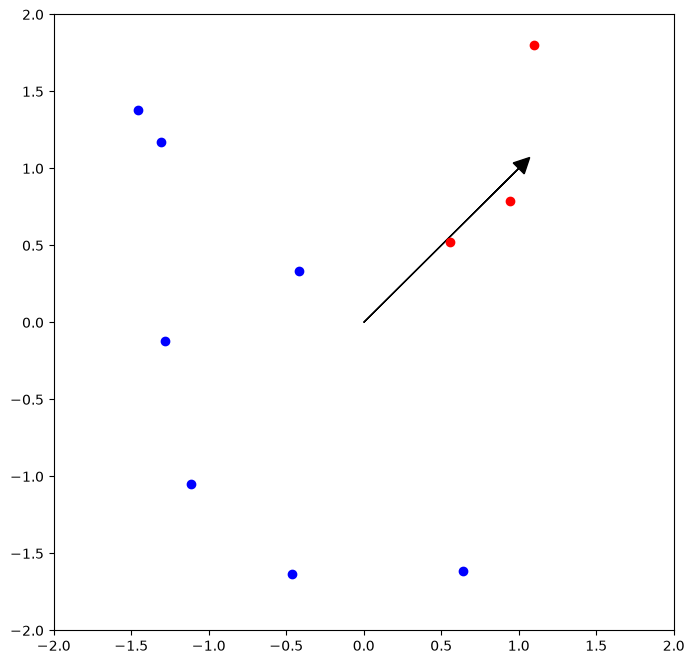

In [11]:
P = np.array([[1, 1]])
fix, ax1 = plt.subplots(figsize=(8, 8))

plot_vectors([P], axes=[2, 2], ax=ax1)

for i in range(0, 10):
    v1 = np.array(np.random.uniform(-2 ,2, 2))
    side_of_plane = np.sign(np.dot(P, v1.T))
    if side_of_plane == 1:
        ax1.plot([v1[0]], [v1[1]], 'ro')
    else:
        ax1.plot([v1[0]], [v1[1]], 'bo')

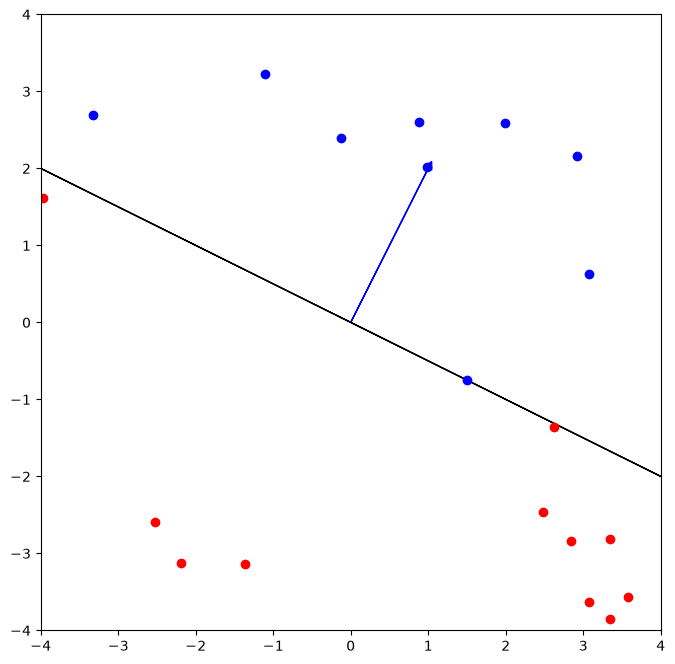

In [14]:
P = np.array([[1, 2]])
PT = np.dot([[0, 1], [-1, 0]], P.T).T

fig, ax1 = plt.subplots(figsize=(8, 8))

plot_vectors([P], colors=['b'], axes=[2, 2], ax=ax1)
plot_vectors([PT * 4, PT * -4], colors=['k', 'k'], axes=[4, 4], ax=ax1)

for i in range(0, 20):
    v1 = np.array(np.random.uniform(-4 ,4, 2))
    side_of_plane = np.sign(np.dot(P, v1.T))

    if side_of_plane == 1:
        ax1.plot([v1[0]], [v1[1]], 'bo')
    else:
        ax1.plot([v1[0]], [v1[1]], 'ro')

In [17]:
P = np.array([[1, 1]])
v1 = np.array([[1, 2]])
v2 = np.array([[-1, 1]])
v3 = np.array([[-2, -1]])

In [20]:
print(np.dot(P, v1.T))
print(np.dot(P, v2.T))
print(np.dot(P, v3.T))

[[3]]
[[0]]
[[-3]]


In [26]:
def side_of_plane(P, v):
    dotproduct = np.dot(P, v.T)
    sign_of_dot_product = np.sign(dotproduct)
    sign_of_dot_product_scalar = sign_of_dot_product.item()
    return sign_of_dot_product_scalar

In [27]:
print(side_of_plane(P, v1))
print(side_of_plane(P, v2))
print(side_of_plane(P, v3))

1
0
-1


In [31]:
P1 = np.array([[1, 1]])
P2 = np.array([[-1, 1]])
P3 = np.array([[-1, -1]])
P_l = [P1, P2, P3]

v = np.array([[2, 2]])

In [32]:
def hash_multi_plane(P_l, v):
    hash_value = 0
    for i, P in enumerate(P_l):
        sign = side_of_plane(P, v)
        hash_i = 1 if sign >= 0 else 0
        hash_value += 2 ** i * hash_i
    return hash_value

In [33]:
print(hash_multi_plane(P_l, v))

3


In [40]:
np.random.seed(0)
num_dimensions = 2
num_planes = 3
random_planes_matrix = np.random.normal(size=(num_planes, num_dimensions))
print(random_planes_matrix)

[[ 1.76405235  0.40015721]
 [ 0.97873798  2.2408932 ]
 [ 1.86755799 -0.97727788]]


In [41]:
v = np.array([[2, 2]])

In [42]:
def side_of_plane_matrix(P, v):
    return np.sign(np.dot(P, v.T))

In [43]:
sides_l = side_of_plane_matrix(random_planes_matrix, v)
print(sides_l)

[[1.]
 [1.]
 [1.]]


In [44]:
def hash_multi_plane_matrix(P, v, num_planes):
    sides_matrix = side_of_plane_matrix(P, v)
    hash_value = 0
    for i in range(num_planes):
        sign = sides_matrix[i].item()
        hash_i = 1 if sign >= 0 else 0
        hash_value += 2 ** i * hash_i
    return hash_value

In [45]:
hash_multi_plane_matrix(random_planes_matrix, v, num_planes)

7

In [46]:
word_embedding = {
    'I': np.array([1, 0, 1]),
    'love': np.array([-1, 0, 1]),
    'learning': np.array([1, 0, 1])
}

words_in_document = ['I', 'love', 'learning', 'not_a_word']
document_embedding = np.array([0, 0, 0])

for word in words_in_document:
    document_embedding += word_embedding.get(word, 0)

print(document_embedding)

[1 0 3]
